# Étape 8 : les z-scores historiques des actions du S&P 500

On applique l'étage 1 de l'allocation par facteurs (étape 7) à des données réelles. Pour chaque mois et chaque action de l'univers, on calcule six z-scores, un par facteur :

| z-score | Caractéristique | Sens |
|---|---|---|
| `z_mkt` | bêta sur 60 mois contre le facteur marché | + |
| `z_smb` | logarithme de la capitalisation boursière | − (petites capitalisations favorisées) |
| `z_hml` | fonds propres / capitalisation | + |
| `z_rmw` | rentabilité d'exploitation / fonds propres | + |
| `z_cma` | croissance de l'actif total sur un an | − (faible investissement favorisé) |
| `z_mom` | rendement de $t-12$ à $t-1$ | + |

Les sources :
- composition historique du S&P 500, mois par mois ;
- cours mensuels de Yahoo Finance ;
- comptes publiés à la SEC (base XBRL d'EDGAR).

Le script [`scripts/telecharger_donnees_sp500.py`](../scripts/telecharger_donnees_sp500.py) les télécharge.

In [1]:
def nombre(n):
    return f"{n:,}".replace(",", " ")


import io
import sys
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "scripts"))
from univers_sp500 import membres_mensuels

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

## 1. L'univers : les membres du S&P 500, mois par mois

Chaque mois, l'univers est la liste des **membres de l'indice à cette date**, et non la liste d'aujourd'hui. Une entreprise sortie de l'indice en 2015 en fait partie jusqu'en 2015. Une entreprise entrée en 2020 n'en fait partie qu'à partir de 2020.

Pourquoi le S&P 500 :
- grandes capitalisations américaines, liquides et investissables, dans la continuité des étapes 4 à 6 ;
- composition historique publique ;
- toutes ces entreprises déposent leurs comptes à la SEC.

In [2]:
membres = membres_mensuels()
print(f"{membres.shape[0]} mois, de {membres.index[0]} à {membres.index[-1]}")
print(f"{membres.shape[1]} tickers différents ont fait partie de l'indice sur la période")
print(f"Membres par mois : entre {membres.sum(axis=1).min()} et {membres.sum(axis=1).max()}")

201 mois, de 2009-12 à 2026-08
847 tickers différents ont fait partie de l'indice sur la période
Membres par mois : entre 497 et 506


## 2. Les données téléchargées

In [3]:
cours = pd.read_csv(RAW / "sp500_cours_mensuels.csv", index_col=0)            # ajusté des divisions
ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)  # ajusté des divisions et dividendes
for t in (cours, ajustes):
    t.index = pd.PeriodIndex(t.index.astype(str).str[:7], freq="M")
cours = cours[~cours.index.duplicated(keep="last")].sort_index()
ajustes = ajustes[~ajustes.index.duplicated(keep="last")].sort_index()

divisions = pd.read_csv(RAW / "sp500_divisions.csv", parse_dates=["date"])
societes = pd.read_csv(RAW / "edgar_societes.csv")
comptes = pd.read_csv(RAW / "edgar_comptes.csv.gz", parse_dates=["debut", "fin", "depose"])
# comptes publiés sous l'ancienne entité juridique (scripts/telecharger_predecesseurs_edgar.py)
fichier_pred = RAW / "edgar_comptes_predecesseurs.csv.gz"
if fichier_pred.exists():
    pred = pd.read_csv(fichier_pred, parse_dates=["debut", "fin", "depose"])
    comptes = (pd.concat([comptes, pred], ignore_index=True).sort_values("depose")
               .drop_duplicates(["ticker", "concept", "unite", "debut", "fin"], keep="first"))
    print(f"Comptes des entités prédécesseures ajoutés pour {pred['ticker'].nunique()} tickers")

avec_cours = [t for t in membres.columns if t in cours.columns and cours[t].notna().any()]
print(f"Cours : {len(avec_cours)} tickers sur {membres.shape[1]} ont un historique sur Yahoo Finance")
print(f"Comptes : {societes['ticker'].nunique()} tickers reconnus par la SEC, "
      f"{comptes['ticker'].nunique()} avec des chiffres XBRL, {nombre(len(comptes))} chiffres au total")
print(f"Divisions d'actions : {len(divisions)} sur {divisions['ticker'].nunique()} titres")

Comptes des entités prédécesseures ajoutés pour 17 tickers
Cours : 641 tickers sur 847 ont un historique sur Yahoo Finance
Comptes : 623 tickers reconnus par la SEC, 623 avec des chiffres XBRL, 191 881 chiffres au total
Divisions d'actions : 1773 sur 444 titres


### Une seule ligne par entreprise

Certaines entreprises ont plusieurs catégories d'actions cotées, toutes deux dans l'indice (Alphabet : GOOGL et GOOG ; Fox ; News Corp...). Elles partagent le même identifiant SEC (CIK) et les mêmes comptes. On ne garde qu'une ligne par entreprise : le ticker présent le plus longtemps dans l'indice. Sinon, la même entreprise compterait deux fois dans les moyennes et les écarts-types des z-scores.

In [4]:
duree = membres.sum()
societes["mois_dans_indice"] = societes["ticker"].map(duree).fillna(0)
doublons = societes[societes.duplicated("cik", keep=False)].sort_values(["cik", "mois_dans_indice"], ascending=[True, False])
garde = societes.sort_values("mois_dans_indice", ascending=False).drop_duplicates("cik")
retires = sorted(set(doublons["ticker"]) - set(garde["ticker"]))
print("Catégories d'actions retirées :", retires)
membres = membres.drop(columns=[t for t in retires if t in membres.columns])
secteur_sic = garde.set_index("ticker")["sic"]

Catégories d'actions retirées : ['FOX', 'GOOG', 'NWS', 'UA']


### Un ticker, une seule entreprise

Un ticker peut être réattribué. « BEAM » désignait Beam Inc. (spiritueux) jusqu'en 2014, puis Beam Therapeutics, entrée en bourse en 2020. La SEC et Yahoo rattachent aujourd'hui le ticker à la société qui le porte actuellement. Utiliser ses comptes ou ses cours pour 2012 mélangerait deux entreprises.

Règle retenue : un couple (mois, ticker) n'est gardé que si l'entreprise rattachée au ticker **publiait des comptes à la SEC à cette date**, c'est-à-dire si son dernier dépôt date de moins de 15 mois. Une société qui n'existait pas encore n'a rien publié et sort automatiquement.

In [5]:
depots = comptes[["ticker", "depose"]].drop_duplicates().sort_values("depose")
grille_membres = membres.rename_axis(index="mois", columns="ticker").stack()
grille_membres = grille_membres[grille_membres].reset_index()[["mois", "ticker"]]
grille_membres["date"] = grille_membres["mois"].dt.to_timestamp(how="end").dt.normalize()
dernier_depot = pd.merge_asof(grille_membres.sort_values("date"), depots, left_on="date", right_on="depose",
                              by="ticker", direction="backward")
dernier_depot["valide"] = (dernier_depot["date"] - dernier_depot["depose"]).dt.days <= 15 * 30.5
valide = dernier_depot.set_index(["mois", "ticker"])["valide"].sort_index()
print(f"Couples (mois, membre) : {nombre(len(valide))}, dont {nombre(int(valide.sum()))} rattachés à une entreprise "
      f"qui publiait à cette date ({valide.mean():.1%})")

Couples (mois, membre) : 100 425, dont 81 536 rattachés à une entreprise qui publiait à cette date (81.2%)


## 3. Les comptes, connus à la bonne date

Chaque chiffre de la base EDGAR porte deux dates :
- `fin` : la date de clôture de la période comptable (par exemple le 31 décembre 2015) ;
- `depose` : la date à laquelle le rapport a été publié (par exemple le 25 février 2016).

À chaque fin de mois $t$, on n'utilise que les chiffres **déjà publiés** ($\text{depose} \le t$), et parmi eux ceux de l'exercice le plus récent. Un chiffre corrigé plus tard n'est pris en compte qu'à partir de la date de la correction : le fichier ne garde que la première publication de chaque chiffre.

On écarte les chiffres trop anciens : plus de 18 mois après la clôture pour les comptes annuels, plus de 12 mois pour le nombre d'actions. Une entreprise qui ne publie plus n'est pas évaluée avec des comptes périmés.

In [6]:
ANNUELS = {"10-K", "10-K/A", "10-KT", "20-F", "40-F"}


def serie_annuelle(concepts, flux):
    # Un chiffre par entreprise et par exercice, le premier concept disponible dans l'ordre de préférence.
    d = comptes[comptes["concept"].isin(concepts) & comptes["formulaire"].isin(ANNUELS)
                & (comptes["unite"] == "USD")].copy()
    if flux:
        jours = (d["fin"] - d["debut"]).dt.days
        d = d[jours.between(330, 400)]
    else:
        d = d[d["debut"].isna()]
    d["rang"] = d["concept"].map({c: i for i, c in enumerate(concepts)})
    d = d.sort_values(["rang", "depose"]).drop_duplicates(["ticker", "fin"])
    return d[["ticker", "fin", "depose", "valeur", "concept"]].reset_index(drop=True)


def a_la_date(serie, colonnes, peremption_mois):
    # Pour chaque (mois, ticker) : la valeur du dernier exercice publié avant la fin du mois.
    s = serie.sort_values("depose").copy()
    s["fin_max"] = s.groupby("ticker")["fin"].cummax()
    s = s[s["fin"] == s["fin_max"]]
    grille = pd.DataFrame([(m, t) for m in membres.index for t in membres.columns[membres.loc[m]]],
                          columns=["mois", "ticker"])
    grille["date"] = grille["mois"].dt.to_timestamp(how="end").dt.normalize()
    sortie = pd.merge_asof(grille.sort_values("date"), s.sort_values("depose")[["ticker", "depose", "fin"] + colonnes],
                           left_on="date", right_on="depose", by="ticker", direction="backward")
    trop_vieux = (sortie["date"] - sortie["fin"]).dt.days > peremption_mois * 30.5
    sortie.loc[trop_vieux, colonnes] = np.nan
    return sortie.set_index(["mois", "ticker"])[colonnes + ["fin"]].sort_index()

### Fonds propres

Fonds propres comptables = capitaux propres des actionnaires (`StockholdersEquity`, ou à défaut `StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest`), moins les actions de préférence (`PreferredStockValue`) quand elles existent. C'est la définition de Fama et French, simplifiée : on ne réintègre pas les impôts différés, qui sont rarement publiés à part dans XBRL.

In [7]:
cp = serie_annuelle(["StockholdersEquity",
                     "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest"], flux=False)
pref = serie_annuelle(["PreferredStockValue"], flux=False)[["ticker", "fin", "valeur"]].rename(columns={"valeur": "pref"})
fonds_propres = cp.merge(pref, on=["ticker", "fin"], how="left")
fonds_propres["fonds_propres"] = fonds_propres["valeur"] - fonds_propres["pref"].fillna(0)
print(f"{len(fonds_propres)} exercices, {fonds_propres['ticker'].nunique()} entreprises")
print(fonds_propres["concept"].value_counts().rename("concept utilisé"))
print(f"Fonds propres négatifs ou nuls : {(fonds_propres['fonds_propres'] <= 0).mean():.1%} des exercices")

11128 exercices, 618 entreprises
concept
StockholdersEquity                                                        9877
StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest    1251
Name: concept utilisé, dtype: int64
Fonds propres négatifs ou nuls : 4.9% des exercices


### Rentabilité d'exploitation (RMW)

Fama et French : (chiffre d'affaires − coût des ventes − frais généraux − charges d'intérêts) / fonds propres. Ces postes sont nommés très différemment d'une entreprise à l'autre dans XBRL. On part donc du **résultat d'exploitation** (`OperatingIncomeLoss`), qui correspond aux trois premiers postes, et on retire les **charges d'intérêts**.

Les banques et les assurances ne publient pas de résultat d'exploitation. Pour elles, on prend le **résultat avant impôts**, qui inclut déjà les charges d'intérêts. Le ratio est calculé seulement quand les fonds propres sont positifs.

In [8]:
CONCEPTS_INTERETS = ["InterestExpense", "InterestExpenseNonoperating", "InterestExpenseDebt"]
CONCEPTS_AVANT_IMPOTS = [
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments",
]
exploitation = serie_annuelle(["OperatingIncomeLoss"], flux=True)
interets = serie_annuelle(CONCEPTS_INTERETS, flux=True)[["ticker", "fin", "valeur"]].rename(columns={"valeur": "interets"})
avant_impots = serie_annuelle(CONCEPTS_AVANT_IMPOTS, flux=True)

resultat = exploitation.merge(interets, on=["ticker", "fin"], how="left")
resultat["resultat"] = resultat["valeur"] - resultat["interets"].fillna(0)
resultat["source"] = "exploitation - intérêts"
complement = avant_impots[~avant_impots.set_index(["ticker", "fin"]).index.isin(resultat.set_index(["ticker", "fin"]).index)]
complement = complement.assign(resultat=complement["valeur"], source="résultat avant impôts")
resultat = pd.concat([resultat, complement], ignore_index=True)

rentab = resultat.merge(fonds_propres[["ticker", "fin", "depose", "fonds_propres"]], on=["ticker", "fin"],
                        suffixes=("", "_fp"))
rentab["depose"] = rentab[["depose", "depose_fp"]].max(axis=1)
rentab["rentabilite"] = np.where(rentab["fonds_propres"] > 0, rentab["resultat"] / rentab["fonds_propres"], np.nan)
print(rentab["source"].value_counts().rename("source du résultat"))

source
exploitation - intérêts    8082
résultat avant impôts      1968
Name: source du résultat, dtype: int64


### Investissement (CMA)

Croissance de l'actif total sur un exercice : $\text{Actif}_{N} / \text{Actif}_{N-1} - 1$, avec les deux bilans annuels successifs (clôtures distantes de 11 à 13 mois).

In [9]:
actif = serie_annuelle(["Assets"], flux=False)
precedent = actif[["ticker", "fin", "depose", "valeur"]].rename(
    columns={"fin": "fin_prec", "depose": "depose_prec", "valeur": "actif_prec"})
actif = actif.sort_values("fin")
precedent = precedent.sort_values("fin_prec")
actif["cible"] = actif["fin"] - pd.Timedelta(days=330)
croissance = pd.merge_asof(actif.sort_values("cible"), precedent, left_on="cible", right_on="fin_prec",
                           by="ticker", direction="backward", tolerance=pd.Timedelta(days=70))
croissance["depose"] = croissance[["depose", "depose_prec"]].max(axis=1)
croissance["croissance_actif"] = np.where(croissance["actif_prec"] > 0,
                                          croissance["valeur"] / croissance["actif_prec"] - 1, np.nan)
croissance = croissance.dropna(subset=["croissance_actif"])
print(f"{len(croissance)} croissances annuelles d'actif, {croissance['ticker'].nunique()} entreprises")

9374 croissances annuelles d'actif, 618 entreprises


### Nombre d'actions et capitalisation

Nombre d'actions : celui de la page de garde des rapports 10-K et 10-Q (`EntityCommonStockSharesOutstanding`), mis à jour chaque trimestre. À défaut, on prend le nombre d'actions du bilan, puis le nombre moyen d'actions de l'exercice.

**Attention aux divisions d'actions.** Les cours de Yahoo sont ajustés des divisions : après la division par 4 d'Apple en août 2020, tout l'historique de cours est divisé par 4. Le nombre d'actions publié à la SEC, lui, est celui de la date du rapport. Si $s$ est la date du nombre d'actions et $F(s)$ le produit des ratios de toutes les divisions postérieures à $s$, la capitalisation en fin de mois $t$ vaut :

$$\text{Capi}_t = \underbrace{P^{\text{ajusté}}_t}_{\text{cours Yahoo}} \times N_s \times F(s)$$

Le cours ajusté multiplié par $F(s)$ redonne le cours dans l'unité du rapport, celle de $N_s$.

**Erreurs d'unité.** Quelques entreprises publient certains trimestres leur nombre d'actions en milliers, ou multiplié par 1 000 (PG&E, Garmin, ConocoPhillips, Huntington...). Une capitalisation fausse d'un facteur 1 000 fausserait le z-score de taille et le ratio fonds propres / capitalisation. Règle de nettoyage, qui n'utilise que les publications passées :
- on ramène chaque nombre d'actions en actions d'aujourd'hui ($N_s \times F(s)$) ;
- on l'écarte s'il diffère de plus d'un facteur 3 du dernier chiffre retenu, ou si la capitalisation qu'il implique sort de 1 à 8 000 milliards de dollars (un membre du S&P 500 vaut au moins 1 milliard) ;
- deux chiffres écartés de suite mais cohérents entre eux signalent un vrai changement (grosse fusion payée en actions) : on les accepte.

In [10]:
CONCEPTS_ACTIONS = ["EntityCommonStockSharesOutstanding", "CommonStockSharesOutstanding",
                    "WeightedAverageNumberOfSharesOutstandingBasic"]
actions = comptes[comptes["concept"].isin(CONCEPTS_ACTIONS) & (comptes["unite"] == "shares")].copy()
actions["rang"] = actions["concept"].map({c: i for i, c in enumerate(CONCEPTS_ACTIONS)})
actions = actions.sort_values(["rang", "depose"]).drop_duplicates(["ticker", "fin"])
actions = actions[actions["valeur"] > 0][["ticker", "fin", "depose", "valeur", "concept"]]
actions = actions.rename(columns={"valeur": "nb_actions"})


def facteur_divisions(tickers, dates):
    # Produit des ratios des divisions strictement postérieures à chaque date.
    sortie = np.ones(len(tickers))
    par_titre = {t: g.sort_values("date") for t, g in divisions.groupby("ticker")}
    for i, (t, d) in enumerate(zip(tickers, dates)):
        g = par_titre.get(t)
        if g is None or pd.isna(d):
            continue
        apres = g.loc[g["date"] > d, "ratio"]
        sortie[i] = apres.prod() if len(apres) else 1.0
    return sortie


cours_long = cours.stack().rename("cours").rename_axis(["mois", "ticker"])

# Nettoyage des erreurs d'unité : nombre d'actions publié en milliers, ou multiplié par 1 000.
actions["n_ajuste"] = actions["nb_actions"] * facteur_divisions(actions["ticker"].values, actions["fin"].values)
actions["mois_fin"] = actions["fin"].dt.to_period("M")
actions = actions.join(cours_long, on=["mois_fin", "ticker"])
actions["capi_fin"] = actions["cours"] * actions["n_ajuste"]


def chiffres_coherents(d):
    # On parcourt les publications dans l'ordre : une valeur est gardée si elle reste dans un rapport 1/3 à 3
    # avec la précédente gardée (nombres ramenés en actions d'aujourd'hui). Deux valeurs rejetées successives
    # et cohérentes entre elles signalent un vrai changement de niveau : on les accepte.
    garde, prec, rejet = [], None, None
    for i, n, capi in zip(d.index, d["n_ajuste"], d["capi_fin"]):
        if pd.notna(capi) and not 1e9 <= capi <= 8e12:
            continue
        if prec is None or 1 / 3 <= n / prec <= 3 or (rejet is not None and 1 / 3 <= n / rejet <= 3):
            garde.append(i)
            prec, rejet = n, None
        else:
            rejet = n
    return garde


avant = len(actions)
garde = [i for _, d in actions.sort_values(["depose", "fin"]).groupby("ticker", sort=False)
         for i in chiffres_coherents(d)]
actions = actions.loc[garde, ["ticker", "fin", "depose", "nb_actions", "concept"]]
print(f"Nombres d'actions écartés comme erreurs d'unité : {nombre(avant - len(actions))} sur {nombre(avant)}")

nb_actions = a_la_date(actions, ["nb_actions"], peremption_mois=12)

cle = nb_actions.reset_index()
cle["F"] = facteur_divisions(cle["ticker"].values, cle["fin"].values)
cle = cle.join(cours_long, on=["mois", "ticker"])
cle["capitalisation"] = cle["cours"] * cle["nb_actions"] * cle["F"]
# Même garde-fou au mois d'utilisation : juste après une scission, la nouvelle société a parfois publié
# le nombre d'actions de la coquille d'avant la cotation (quelques centaines d'actions).
cle["capitalisation"] = cle["capitalisation"].where(cle["capitalisation"].between(1e9, 8e12))
capitalisation = cle.set_index(["mois", "ticker"])["capitalisation"]
print(f"Capitalisations calculées : {nombre(capitalisation.notna().sum())} couples (mois, action)")

Nombres d'actions écartés comme erreurs d'unité : 1 617 sur 68 359


Capitalisations calculées : 79 901 couples (mois, action)


In [11]:
# Contrôle : la capitalisation doit être cohérente dans le temps et avec les ordres de grandeur connus.
controle = capitalisation.unstack()
for t in ["AAPL", "MSFT", "XOM", "JPM"]:
    if t in controle.columns:
        s = controle[t].dropna()
        if len(s):
            print(f"{t} : {s.iloc[0] / 1e9:,.0f} Md$ en {s.index[0]}, {s.iloc[-1] / 1e9:,.0f} Md$ en {s.index[-1]}")
sauts = (controle / controle.shift(1)).stack()
print(f"Variations mensuelles de capitalisation au-delà d'un facteur 3 : {((sauts > 3) | (sauts < 1 / 3)).sum()}")

AAPL : 190 Md$ en 2009-12, 4,624 Md$ en 2026-08
MSFT : 271 Md$ en 2009-12, 3,767 Md$ en 2026-08
XOM : 324 Md$ en 2009-12, 662 Md$ en 2026-08
JPM : 164 Md$ en 2009-12, 946 Md$ en 2026-08
Variations mensuelles de capitalisation au-delà d'un facteur 3 : 8


## 4. Les six caractéristiques, mois par mois

In [12]:
fp_mois = a_la_date(fonds_propres.rename(columns={"valeur": "_"}), ["fonds_propres"], peremption_mois=18)
rentab_mois = a_la_date(rentab, ["rentabilite"], peremption_mois=18)
croiss_mois = a_la_date(croissance, ["croissance_actif"], peremption_mois=18)

carac = pd.DataFrame(index=fp_mois.index)
carac["capitalisation"] = capitalisation.reindex(carac.index)
carac["log_capi"] = np.log(carac["capitalisation"])
carac["fonds_propres_sur_capi"] = np.where(fp_mois["fonds_propres"] > 0,
                                           fp_mois["fonds_propres"] / carac["capitalisation"], np.nan)
carac["rentabilite"] = rentab_mois["rentabilite"]
carac["croissance_actif"] = croiss_mois["croissance_actif"]

### Momentum

Rendement cumulé de la fin du mois $t-12$ à la fin du mois $t-1$, avec les cours ajustés des dividendes. On saute le dernier mois $t$, comme Fama et French : sur un mois, les rendements ont tendance à s'inverser, ce qui brouillerait le signal.

In [13]:
momentum = ajustes.shift(1) / ajustes.shift(12) - 1
carac["momentum"] = momentum.stack().reindex(carac.index)

### Bêta de marché

Il n'y a pas de caractéristique comptable pour le facteur marché : chaque action y est exposée. On mesure donc l'exposition elle-même, le **bêta** estimé sur les 60 derniers mois (au moins 36 mois de données) :

$$\beta_{i,t} = \frac{\mathrm{Cov}(R_i - R_f,\ \mathrm{MKT})}{\mathrm{Var}(\mathrm{MKT})} \quad \text{sur les mois } t-59 \text{ à } t$$

Le facteur marché et le taux sans risque sont ceux de Kenneth French (étape 3).

In [14]:
def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float)


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")

rendements = 100 * ajustes.pct_change(fill_method=None)
exces = rendements.sub(facteurs["RF"].reindex(rendements.index), axis=0)
marche = facteurs["Mkt-RF"].reindex(rendements.index)
M = exces.notna().mul(marche, axis=0).where(exces.notna())   # le marché, sur les seuls mois où l'action a un cours
fen = dict(window=60, min_periods=36)
cov = (exces * M).rolling(**fen).mean() - exces.rolling(**fen).mean() * M.rolling(**fen).mean()
var = (M ** 2).rolling(**fen).mean() - M.rolling(**fen).mean() ** 2
beta = cov / var
carac["beta"] = beta.stack().reindex(carac.index)
carac.describe(percentiles=[0.01, 0.5, 0.99]).T.drop(columns="count")

,mean,std,min,1%,50%,99%,max
capitalisation,6.398e+10,1.914e+11,1.045e+09,3.614e+09,2.447e+10,5.522e+11,5.321e+12
log_capi,2.408e+01,1.094e+00,2.077e+01,2.201e+01,2.392e+01,2.704e+01,2.930e+01
fonds_propres_sur_capi,3.968e-01,4.501e-01,4.894e-06,1.155e-02,3.010e-01,1.622e+00,2.396e+01
rentabilite,6.303e-02,2.278e+01,-1.540e+03,-4.839e-01,2.025e-01,3.664e+00,1.039e+02
croissance_actif,5.418e+01,4.479e+03,-1.000e+00,-2.588e-01,4.841e-02,1.202e+00,3.814e+05
momentum,1.553e-01,4.507e-01,-9.954e-01,-4.860e-01,1.206e-01,1.250e+00,5.198e+01
beta,1.039e+00,5.077e-01,-1.176e+00,8.700e-02,1.014e+00,2.567e+00,4.809e+00


## 5. Des caractéristiques aux z-scores

Pour chaque mois, sur les membres de l'indice qui ont la caractéristique :

1. **Écrêtage** aux 1er et 99e centiles du mois : quelques valeurs aberrantes (fonds propres minuscules, croissance d'actif de +500 % après une fusion) ne doivent pas écraser les autres scores.
2. **Standardisation** : $z_{i,t} = \pm (x_{i,t} - \bar x_t) / \sigma_t$, avec la moyenne et l'écart-type du mois, sur toutes les actions (poids égaux).
3. **Plafond** à ±3.

Le signe est mis pour que plus haut = plus exposé au facteur dans le sens où la prime le rémunère : $-$ pour la taille (on préfère les petites) et pour l'investissement (on préfère celles qui investissent peu).

Les z-scores sont calculés sur l'ensemble de l'univers, sans neutralisation sectorielle, comme les facteurs de Fama et French. Le code SIC de chaque entreprise est conservé dans la base pour permettre une version par secteur plus tard.

In [15]:
CARACTERISTIQUES = {
    "z_mkt": ("beta", +1),
    "z_smb": ("log_capi", -1),
    "z_hml": ("fonds_propres_sur_capi", +1),
    "z_rmw": ("rentabilite", +1),
    "z_cma": ("croissance_actif", -1),
    "z_mom": ("momentum", +1),
}


def zscore_du_mois(x):
    x = x.dropna()
    if len(x) < 30:
        return pd.Series(np.nan, index=x.index)
    bas, haut = x.quantile([0.01, 0.99])
    x = x.clip(bas, haut)
    return ((x - x.mean()) / x.std()).clip(-3, 3)


carac = carac[valide.reindex(carac.index).fillna(False).values]
z = pd.DataFrame(index=carac.index)
for nom, (col, signe) in CARACTERISTIQUES.items():
    z[nom] = signe * carac[col].groupby(level="mois", group_keys=False).apply(zscore_du_mois).reindex(carac.index)

## 6. Couverture : combien de membres de l'indice ont leurs z-scores ?

In [16]:
n_membres = membres.sum(axis=1)
couverture = z.notna().groupby(level="mois").sum()
couverture["six z-scores"] = z.notna().all(axis=1).groupby(level="mois").sum()
part = couverture.div(n_membres, axis=0)
resume = (100 * part).groupby(part.index.year).mean()
resume.round(0)

,z_mkt,z_smb,z_hml,z_rmw,z_cma,z_mom,six z-scores
mois,,,,,,,
2009,51.0,51.0,0.0,0.0,0.0,51.0,0.0
2010,57.0,57.0,24.0,24.0,44.0,57.0,15.0
2011,65.0,64.0,53.0,44.0,63.0,66.0,40.0
2012,67.0,67.0,62.0,58.0,68.0,68.0,55.0
2013,69.0,69.0,66.0,63.0,70.0,70.0,60.0
2014,70.0,70.0,67.0,63.0,71.0,71.0,61.0
2015,72.0,72.0,69.0,65.0,74.0,73.0,63.0
2016,75.0,75.0,72.0,69.0,77.0,76.0,67.0
2017,78.0,78.0,73.0,72.0,79.0,79.0,69.0


In [17]:
# Pourquoi des membres n'ont pas de z-score : les causes, sur toute la période
grille = pd.DataFrame(index=valide.index)
grille["ticker rattaché à une autre entreprise ou sans dépôt récent"] = ~valide
grille["pas de cours Yahoo"] = ~grille.index.get_level_values("ticker").isin(avec_cours)
grille["pas de comptes SEC"] = ~grille.index.get_level_values("ticker").isin(comptes["ticker"].unique())
grille["fonds propres négatifs"] = (fp_mois["fonds_propres"] <= 0).reindex(grille.index).fillna(False)
(100 * grille.mean()).round(1).rename("% des couples (mois, membre)")

ticker rattaché à une autre entreprise ou sans dépôt récent    18.8
pas de cours Yahoo                                             15.4
pas de comptes SEC                                             17.0
fonds propres négatifs                                          3.4
Name: % des couples (mois, membre), dtype: float64

In [18]:
# Début de la base : premier mois où au moins la moitié des membres ont leurs six z-scores
SEUIL = 0.5
DEBUT_BASE = part.index[(part["six z-scores"] >= SEUIL).values.argmax()]
print("Début retenu pour la base finale :", DEBUT_BASE)
print(f"Part des membres avec les six z-scores : {part['six z-scores'].loc[DEBUT_BASE]:.0%} au début, "
      f"{part['six z-scores'].iloc[-1]:.0%} au dernier mois")

Début retenu pour la base finale : 2012-02
Part des membres avec les six z-scores : 57% au début, 88% au dernier mois


## 7. La base finale

In [19]:
DIVISIONS_SIC = [(100, 999, "Agriculture"), (1000, 1499, "Mines, pétrole et gaz"), (1500, 1799, "Construction"),
                 (2000, 3999, "Industrie manufacturière"), (4000, 4999, "Transports, télécoms, services publics"),
                 (5000, 5199, "Commerce de gros"), (5200, 5999, "Commerce de détail"),
                 (6000, 6799, "Finance, assurance, immobilier"), (7000, 8999, "Services"),
                 (9100, 9999, "Administration")]


def division_sic(code):
    if pd.isna(code):
        return np.nan
    return next((nom for a, b, nom in DIVISIONS_SIC if a <= int(code) <= b), np.nan)


base = carac.join(z)
base = base[base.index.get_level_values("mois") >= DEBUT_BASE]
base = base[base[list(CARACTERISTIQUES)].notna().any(axis=1)]
tick = base.index.get_level_values("ticker")
base.insert(0, "secteur_sic", [division_sic(secteur_sic.get(t)) for t in tick])
base.insert(0, "sic", [secteur_sic.get(t) for t in tick])
base.to_csv(OUT / "zscores_sp500_mensuels.csv.gz", float_format="%.6g")
print(f"Base : {nombre(len(base))} lignes (mois, action), {base.index.get_level_values('ticker').nunique()} actions, "
      f"{base.index.get_level_values('mois').nunique()} mois")
base.head()

Base : 73 515 lignes (mois, action), 598 actions, 175 mois


sic               secteur_sic  capitalisation  log_capi  fonds_propres_sur_capi  rentabilite  croissance_actif  momentum  \
mois    ticker                                                                                                                              
2012-02 A       3826  Industrie manufacturière       1.519e+10    23.444                   0.284        0.229            -0.066     0.009   
        AAPL    3571  Industrie manufacturière       5.058e+11    26.949                   0.151        0.441             0.548     0.292   
        ABT     2834  Industrie manufacturière       8.901e+10    25.212                   0.275        0.214             0.014     0.167   
        ACN     7389                  Services       3.836e+10    24.370                   0.101        0.891             0.226     0.136   
        ADBE    7372                  Services       1.624e+10    23.511                   0.356        0.179             0.104    -0.103   

                 beta  z_mkt  z_smb  z_hml  z_rmw  z_cma  z_mom  
mois    ticker                                                   
2012-02 A       1.519  0.710  0.092 -0.549 -0.202  0.860 -0.008  
        AAPL    1.228  0.182 -2.523 -0.877  0.566 -2.257  1.423  
        ABT     0.294 -1.510 -1.624 -0.572 -0.256  0.456  0.791  
        ACN     0.794 -0.604 -0.807 -1.001  2.191 -0.620  0.634  
        ADBE    1.531  0.732  0.027 -0.370 -0.383 -0.005 -0.575

In [20]:
# Statistiques des z-scores (toutes dates confondues)
z_base = base[list(CARACTERISTIQUES)]
pd.DataFrame({
    "valeurs": z_base.notna().sum(),
    "moyenne": z_base.mean(),
    "écart-type": z_base.std(),
    "% au plafond ±3": 100 * (z_base.abs() >= 3).mean(),
    "asymétrie": z_base.skew(),
}).round(2)

,valeurs,moyenne,écart-type,% au plafond ±3,asymétrie
z_mkt,72149,-0.00,0.99,0.65,0.36
z_smb,72115,0.00,1.00,0.41,-0.65
z_hml,66992,-0.01,0.97,1.74,1.22
z_rmw,64914,-0.05,0.73,2.16,2.32
z_cma,73091,0.04,0.81,2.32,-1.58
z_mom,72908,-0.01,0.97,1.10,0.48


In [21]:
# Corrélation moyenne entre z-scores : calculée chaque mois en coupe, puis moyennée
corr_z = z_base.groupby(level="mois").corr().groupby(level=1).mean().loc[list(CARACTERISTIQUES), list(CARACTERISTIQUES)]
corr_z.round(2)

,z_mkt,z_smb,z_hml,z_rmw,z_cma,z_mom
z_mkt,1.00,0.14,0.14,-0.05,0.02,0.00
z_smb,0.14,1.00,0.21,-0.16,0.07,-0.20
z_hml,0.14,0.21,1.00,-0.47,0.14,-0.26
z_rmw,-0.05,-0.16,-0.47,1.00,-0.02,0.05
z_cma,0.02,0.07,0.14,-0.02,1.00,-0.05
z_mom,0.00,-0.20,-0.26,0.05,-0.05,1.00


In [22]:
# Persistance : corrélation de rang entre le z-score d'une action au mois t et au mois t+h
def persistance(col, h):
    w = z_base[col].unstack()
    valeurs = [w.iloc[i].corr(w.iloc[i + h], method="spearman") for i in range(len(w) - h)]
    return np.nanmean(valeurs)


persist = pd.DataFrame({f"{h} mois": [persistance(c, h) for c in CARACTERISTIQUES] for h in [1, 3, 12]},
                       index=list(CARACTERISTIQUES))
persist.round(2)

,1 mois,3 mois,12 mois
z_mkt,0.99,0.98,0.92
z_smb,1.00,0.99,0.96
z_hml,0.99,0.98,0.93
z_rmw,0.99,0.96,0.82
z_cma,0.94,0.82,0.26
z_mom,0.90,0.70,-0.02


In [23]:
# Répartition sectorielle de l'univers au dernier mois
dernier = base.index.get_level_values("mois").max()
base.xs(dernier, level="mois")["secteur_sic"].value_counts().rename("nombre d'actions").to_frame()

,nombre d'actions
secteur_sic,
Industrie manufacturière,201
"Finance, assurance, immobilier",98
Services,75
"Transports, télécoms, services publics",64
Commerce de détail,30
"Mines, pétrole et gaz",13
Commerce de gros,10
Construction,8
Agriculture,1


In [24]:
# Les cinq actions les plus exposées à chaque facteur au dernier mois
d = base.xs(dernier, level="mois")
pd.DataFrame({nom: d[nom].nlargest(5).index.tolist() for nom in CARACTERISTIQUES})

,z_mkt,z_smb,z_hml,z_rmw,z_cma,z_mom
0,AMD,BLDR,ARE,AAPL,BAX,AMAT
1,APP,MOS,EG,APP,DD,AMD
2,COIN,NCLH,KHC,CL,DLTR,CIEN
3,CVNA,TAP,LEN,CLX,ECHO,COHR
4,HOOD,TTD,MOS,COR,FTV,DELL


## 8. Vérification : les z-scores reproduisent-ils les facteurs de Fama et French ?

Si les z-scores mesurent bien les bonnes caractéristiques, un portefeuille qui achète les meilleurs scores et vend les moins bons doit évoluer comme le facteur de Fama et French correspondant. Ce contrôle n'est pas une stratégie : il sert à vérifier les calculs.

- Chaque fin de mois $t$ : on achète les 30 % d'actions au z-score le plus élevé et on vend les 30 % au z-score le plus bas, chaque jambe étant pondérée par la capitalisation, comme chez Fama et French.
- On mesure le rendement de ce portefeuille au mois $t+1$, puis sa corrélation avec le facteur de French du même mois.
- Pour le marché, le portefeuille « bêta élevé moins bêta faible » n'est pas le facteur marché. Mais il doit être fortement corrélé à lui, puisqu'il est net acheteur de bêta.

L'univers n'est pas le même que celui de French : 500 grandes capitalisations au lieu de toutes les actions américaines cotées. Une corrélation parfaite n'est donc pas attendue, surtout pour la taille.

In [25]:
FACTEUR_FRENCH = {"z_mkt": "Mkt-RF", "z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
rend_suivant = rendements.shift(-1).stack().rename("r_suivant").rename_axis(["mois", "ticker"])


def facteur_maison(col):
    d = base[[col, "capitalisation"]].join(rend_suivant).dropna()
    sortie = {}
    for m, g in d.groupby(level="mois"):
        bas, haut = g[col].quantile([0.3, 0.7])
        hautes, basses = g[g[col] >= haut], g[g[col] <= bas]
        r_h = np.average(hautes["r_suivant"], weights=hautes["capitalisation"])
        r_b = np.average(basses["r_suivant"], weights=basses["capitalisation"])
        sortie[m + 1] = r_h - r_b
    return pd.Series(sortie)


maison = pd.DataFrame({c: facteur_maison(c) for c in CARACTERISTIQUES})
communs = maison.index.intersection(facteurs.index)
verification = pd.DataFrame({
    "facteur French": [FACTEUR_FRENCH[c] for c in CARACTERISTIQUES],
    "corrélation": [maison.loc[communs, c].corr(facteurs.loc[communs, FACTEUR_FRENCH[c]]) for c in CARACTERISTIQUES],
    "mois": len(communs),
}, index=list(CARACTERISTIQUES))
verification.round(2)

,facteur French,corrélation,mois
z_mkt,Mkt-RF,0.60,174
z_smb,SMB,0.63,174
z_hml,HML,0.87,174
z_rmw,RMW,0.53,174
z_cma,CMA,0.68,174
z_mom,Mom,0.88,174


## 9. Graphiques

In [26]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS_BANDE = "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")

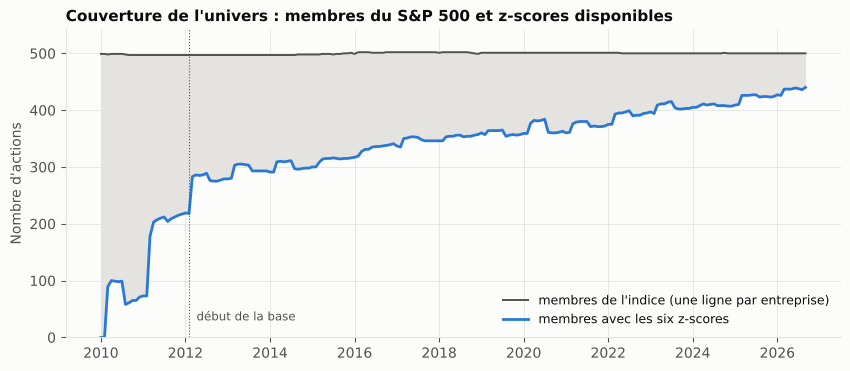

In [27]:
# Couverture de l'univers dans le temps
fig, ax = plt.subplots(figsize=(10, 4))
dates = n_membres.index.to_timestamp(how="end")
ax.plot(dates, n_membres, color=TEXTE2, lw=1.4, label="membres de l'indice (une ligne par entreprise)")
ax.plot(dates, couverture["six z-scores"], color=BLEU, lw=2, label="membres avec les six z-scores")
ax.fill_between(dates, couverture["six z-scores"], n_membres, color=GRIS_BANDE, lw=0)
ax.axvline(DEBUT_BASE.to_timestamp(), color=TEXTE2, lw=0.8, ls=":")
ax.text(DEBUT_BASE.to_timestamp(), 30, "  début de la base", color=TEXTE2, fontsize=8.5)
ax.set_ylim(0, n_membres.max() * 1.08)
ax.set_ylabel("Nombre d'actions")
ax.set_title("Couverture de l'univers : membres du S&P 500 et z-scores disponibles")
ax.legend(loc="lower right", fontsize=9)
sauver(fig, "zscores_couverture.png")
plt.show()

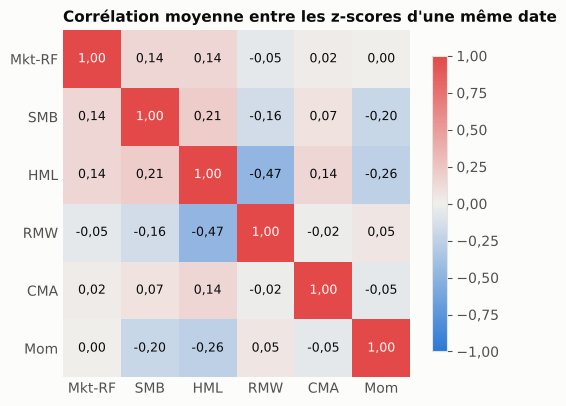

In [28]:
# Corrélation moyenne entre z-scores
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
noms = [FACTEUR_FRENCH[c] for c in CARACTERISTIQUES]
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(corr_z.values, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(noms)):
    for j in range(len(noms)):
        v = corr_z.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else TEXTE)
ax.set_xticks(range(len(noms)), noms)
ax.set_yticks(range(len(noms)), noms)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Corrélation moyenne entre les z-scores d'une même date")
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",").replace("-", "−")))
sauver(fig, "zscores_correlations.png")
plt.show()

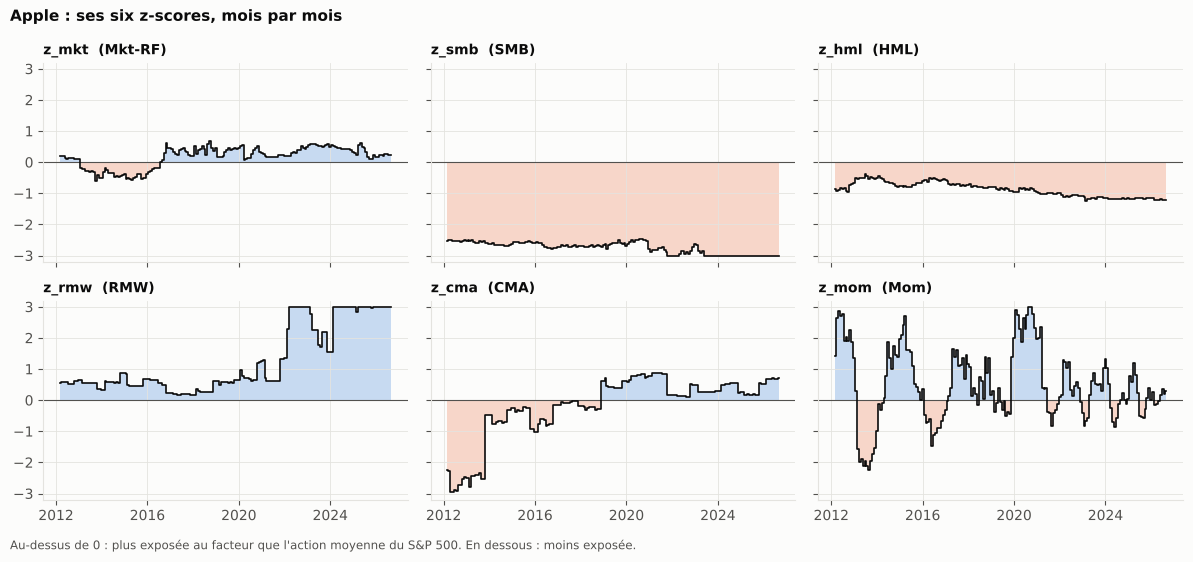

In [29]:
# Les z-scores d'Apple dans le temps
if "AAPL" in base.index.get_level_values("ticker"):
    a = base.xs("AAPL", level="ticker")[list(CARACTERISTIQUES)]
    fig, axes = plt.subplots(2, 3, figsize=(12, 5.4), sharex=True, sharey=True)
    for ax, c in zip(axes.ravel(), CARACTERISTIQUES):
        d = a.index.to_timestamp(how="end")
        ax.axhline(0, color=TEXTE2, lw=0.8)
        ax.fill_between(d, 0, a[c], where=a[c] >= 0, color=BLEU, alpha=0.25, lw=0, step="mid")
        ax.fill_between(d, 0, a[c], where=a[c] < 0, color=ORANGE, alpha=0.25, lw=0, step="mid")
        ax.plot(d, a[c], color=TEXTE, lw=1.2, drawstyle="steps-mid")
        ax.set_title(f"{c}  ({FACTEUR_FRENCH[c]})", fontsize=10)
        ax.set_ylim(-3.2, 3.2)
        ax.xaxis.set_major_locator(mdates.YearLocator(4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.suptitle("Apple : ses six z-scores, mois par mois", x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.text(0.01, -0.02, "Au-dessus de 0 : plus exposée au facteur que l'action moyenne du S&P 500. "
             "En dessous : moins exposée.", fontsize=8.5, color=TEXTE2)
    fig.tight_layout()
    sauver(fig, "zscores_apple.png")
    plt.show()

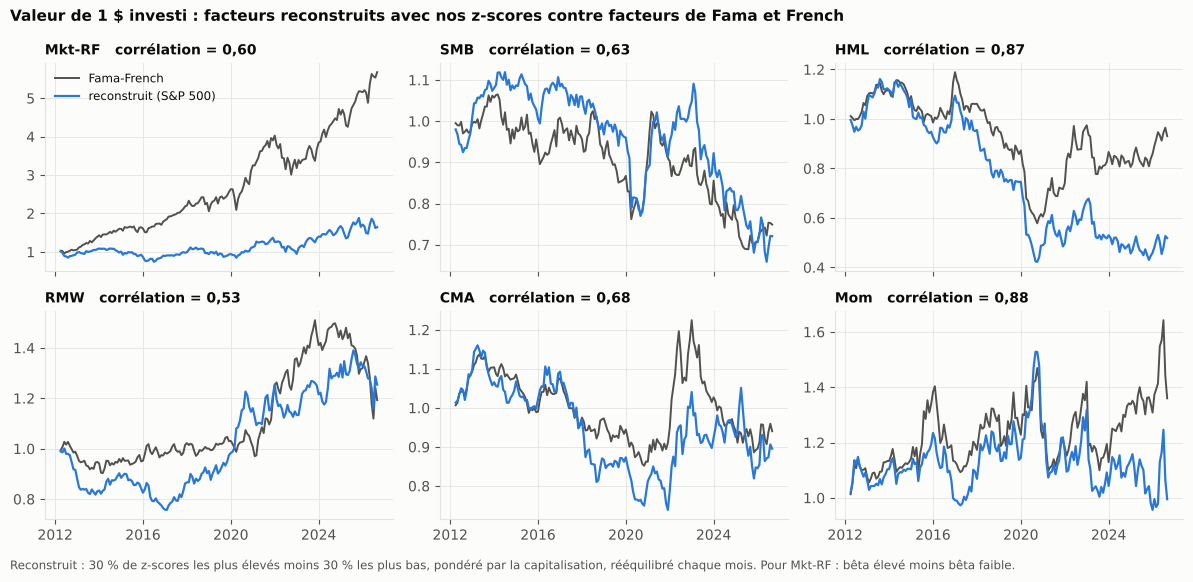

In [30]:
# Vérification : facteurs reconstruits contre facteurs de Fama et French
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True)
for ax, c in zip(axes.ravel(), CARACTERISTIQUES):
    f = FACTEUR_FRENCH[c]
    d = communs.to_timestamp(how="end")
    ax.plot(d, (1 + facteurs.loc[communs, f] / 100).cumprod(), color=TEXTE2, lw=1.4, label="Fama-French")
    ax.plot(d, (1 + maison.loc[communs, c] / 100).cumprod(), color=BLEU, lw=1.6, label="reconstruit (S&P 500)")
    ax.set_title(f"{f}   corrélation = {verification.loc[c, 'corrélation']:.2f}".replace(".", ","), fontsize=10)
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Valeur de 1 $ investi : facteurs reconstruits avec nos z-scores contre facteurs de Fama et French",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.text(0.01, -0.02, "Reconstruit : 30 % de z-scores les plus élevés moins 30 % les plus bas, pondéré par la "
         "capitalisation, rééquilibré chaque mois. Pour Mkt-RF : bêta élevé moins bêta faible.",
         fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "zscores_verification_french.png")
plt.show()